Import all required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from IPython.display import display

from sklearn.ensemble import GradientBoostingRegressor

from sklearn.model_selection import (
    KFold,
    cross_validate,
    cross_val_predict,
    learning_curve
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.base import clone

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.


Set project paths and output folders

In [2]:
project_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project"
)

processed_dir = project_dir / "data" / "processed"

models_dir = project_dir / "models"

output_dir = (
    project_dir / "output" /
    "gradient_boosting" / "best_model"
)

models_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

def save_plot(filename):
    plt.savefig(
        output_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("Project:", project_dir)
print("Visualizations:", output_dir)
print("Saved models:", models_dir)

Project: C:\Users\U S E R\Desktop\ML Assigment\project
Visualizations: C:\Users\U S E R\Desktop\ML Assigment\project\output\gradient_boosting\best_model
Saved models: C:\Users\U S E R\Desktop\ML Assigment\project\models


Load the preprocessed training dataset

In [3]:
train_df = pd.read_csv(
    processed_dir / "math_train_processed.csv"
)

X_train = train_df.drop(columns=["G3"])
y_train = train_df["G3"]

print("Training samples:", X_train.shape[0])
print("Input features:", X_train.shape[1])

display(train_df.head())

Training samples: 316
Input features: 58


,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,...,cat__activities_yes,cat__nursery_no,cat__nursery_yes,cat__higher_no,cat__higher_yes,cat__internet_no,cat__internet_yes,cat__romantic_no,cat__romantic_yes,G3
0,-0.5,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,12
1,-0.5,-0.5,0.0,1.0,-1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,14
2,-0.5,-1.0,0.0,0.0,0.0,3.0,0.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0
3,-0.5,0.5,0.0,0.0,1.0,0.0,-1.0,1.0,0.5,1.0,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,9
4,-0.5,-0.5,-2.0,1.0,-1.0,0.0,-1.0,0.0,-0.5,0.0,...,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,8


Verify the training data

In [4]:
print("Missing feature values:", X_train.isna().sum().sum())
print("Missing target values:", y_train.isna().sum())

print("Target minimum:", y_train.min())
print("Target maximum:", y_train.max())

print("Target included in features:", "G3" in X_train.columns)

assert "G3" not in X_train.columns
assert X_train.isna().sum().sum() == 0
assert y_train.isna().sum() == 0
assert X_train.select_dtypes(exclude="number").empty

print("\nTraining dataset verification successful.")


Missing feature values: 0
Missing target values: 0
Target minimum: 0
Target maximum: 20
Target included in features: False

Training dataset verification successful.


Initialize the final GB-5 model


In [5]:
gb5_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=4,
    min_samples_leaf=2,
    subsample=1.0,
    random_state=42
)

print("Selected model:")
print(gb5_model)

Selected model:
GradientBoostingRegressor(max_depth=4, min_samples_leaf=2, n_estimators=300,
                          random_state=42)


Configure five-fold cross-validation

In [6]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "R2": "r2"
}

print("Cross-validation configured.")

Cross-validation configured.


Train and evaluate GB-5 using cross-validation

In [7]:
cv_scores = cross_validate(
    gb5_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    error_score="raise"
)

train_mae = -cv_scores["train_MAE"].mean()
val_mae = -cv_scores["test_MAE"].mean()

train_mse = -cv_scores["train_MSE"].mean()
val_mse = -cv_scores["test_MSE"].mean()

train_rmse = np.sqrt(
    -cv_scores["train_MSE"]
).mean()

val_rmse = np.sqrt(
    -cv_scores["test_MSE"]
).mean()

train_r2 = cv_scores["train_R2"].mean()
val_r2 = cv_scores["test_R2"].mean()

rmse_gap = val_rmse - train_rmse

print("=" * 60)
print("GB-5 CROSS-VALIDATION RESULTS")
print("=" * 60)

print(f"Train MAE       : {train_mae:.4f}")
print(f"Validation MAE  : {val_mae:.4f}")

print(f"Train MSE       : {train_mse:.4f}")
print(f"Validation MSE  : {val_mse:.4f}")

print(f"Train RMSE      : {train_rmse:.4f}")
print(f"Validation RMSE : {val_rmse:.4f}")

print(f"Train R²        : {train_r2:.4f}")
print(f"Validation R²   : {val_r2:.4f}")

print(f"RMSE Gap        : {rmse_gap:.4f}")

GB-5 CROSS-VALIDATION RESULTS
Train MAE       : 0.0251
Validation MAE  : 0.9385
Train MSE       : 0.0017
Validation MSE  : 2.1579
Train RMSE      : 0.0410
Validation RMSE : 1.4427
Train R²        : 0.9999
Validation R²   : 0.8950
RMSE Gap        : 1.4017


Create a table of the five individual folds

In [8]:
fold_results = pd.DataFrame({
    "Fold": np.arange(1, 6),

    "Train MAE": -cv_scores["train_MAE"],
    "Validation MAE": -cv_scores["test_MAE"],

    "Train RMSE": np.sqrt(
        -cv_scores["train_MSE"]
    ),

    "Validation RMSE": np.sqrt(
        -cv_scores["test_MSE"]
    ),

    "Train R2": cv_scores["train_R2"],
    "Validation R2": cv_scores["test_R2"]
})

display(fold_results.round(4))

fold_results.to_csv(
    output_dir / "GB5_Cross_Validation_Folds.csv",
    index=False
)

,Fold,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R2,Validation R2
0,1,0.0283,0.9067,0.0469,1.3322,0.9999,0.8764
1,2,0.0247,1.1444,0.0414,1.7956,0.9999,0.8929
2,3,0.0274,0.8780,0.0438,1.2712,0.9999,0.8850
3,4,0.0215,0.7833,0.0344,1.0805,0.9999,0.9414
4,5,0.0235,0.9801,0.0387,1.7341,0.9999,0.8791


Visualize training vs validation performance

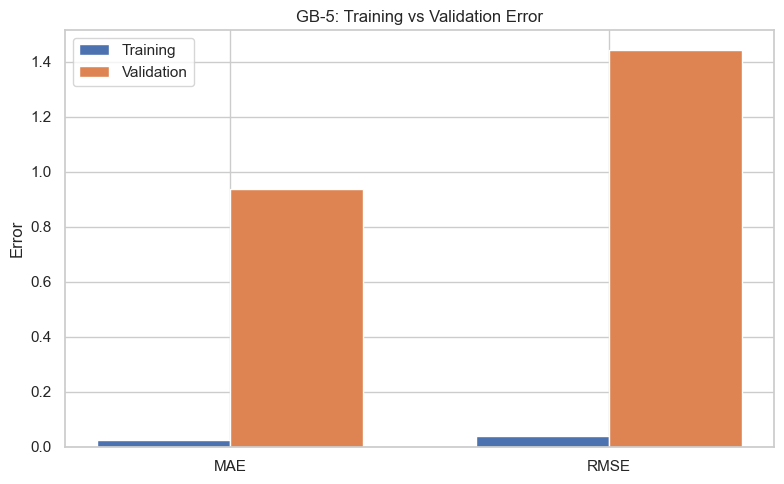

In [9]:
metrics = ["MAE", "RMSE"]

training_values = [train_mae, train_rmse]
validation_values = [val_mae, val_rmse]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    training_values,
    width,
    label="Training"
)

plt.bar(
    x + width / 2,
    validation_values,
    width,
    label="Validation"
)

plt.xticks(x, metrics)
plt.ylabel("Error")
plt.title("GB-5: Training vs Validation Error")
plt.legend()

plt.tight_layout()

save_plot("GB5_Training_vs_Validation_Error.png")

Visualize RMSE across the five folds

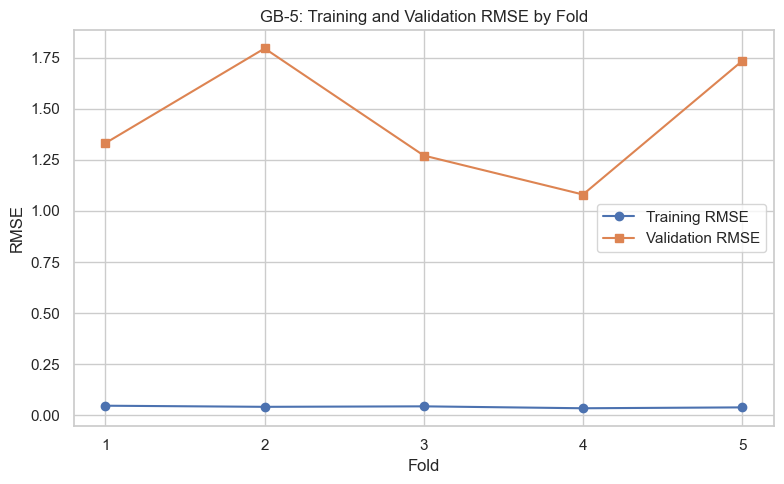

In [10]:
plt.figure(figsize=(8, 5))

x = np.arange(1, 6)

plt.plot(
    x,
    fold_results["Train RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    x,
    fold_results["Validation RMSE"],
    marker="s",
    label="Validation RMSE"
)

plt.xlabel("Fold")
plt.ylabel("RMSE")
plt.title("GB-5: Training and Validation RMSE by Fold")

plt.xticks(x)
plt.legend()

plt.tight_layout()

save_plot("GB5_RMSE_By_Fold.png")

Generate out-of-fold predictions

In [11]:
oof_predictions = cross_val_predict(
    gb5_model,
    X_train,
    y_train,
    cv=cv
)

actual = y_train.to_numpy()

residuals = actual - oof_predictions

print("OOF predictions generated:", len(oof_predictions))

prediction_df = pd.DataFrame({
    "Actual G3": actual,
    "Predicted G3": oof_predictions,
    "Residual": residuals,
    "Absolute Error": np.abs(residuals)
})

display(prediction_df.head())

prediction_df.to_csv(
    output_dir / "GB5_OOF_Predictions.csv",
    index=False
)

OOF predictions generated: 316


,Actual G3,Predicted G3,Residual,Absolute Error
0,12,12.352774,-0.352774,0.352774
1,14,14.325167,-0.325167,0.325167
2,0,1.059464,-1.059464,1.059464
3,9,8.441442,0.558558,0.558558
4,8,8.390669,-0.390669,0.390669


Visualize actual vs predicted grades

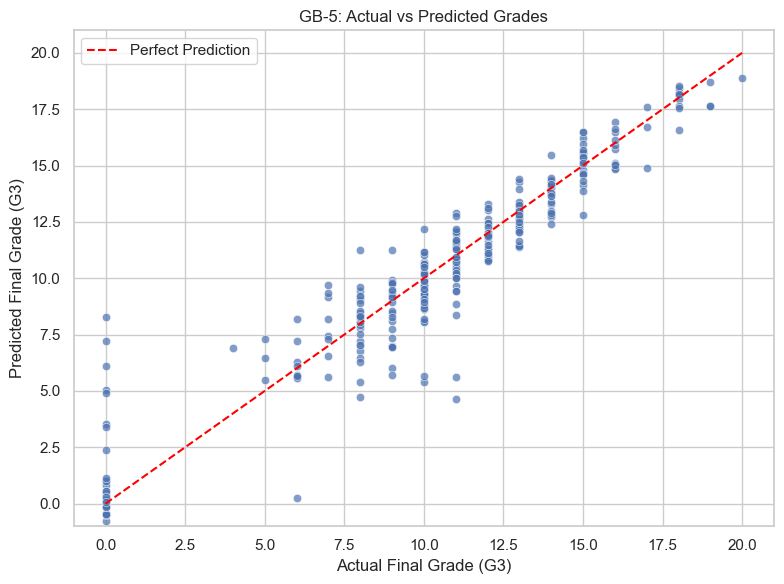

In [12]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=actual,
    y=oof_predictions,
    alpha=0.7
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade (G3)")

plt.title("GB-5: Actual vs Predicted Grades")
plt.legend()

plt.xlim(-1, 21)
plt.ylim(-1, 21)

plt.tight_layout()

save_plot("GB5_Actual_vs_Predicted.png")

Visualize residuals vs predictions

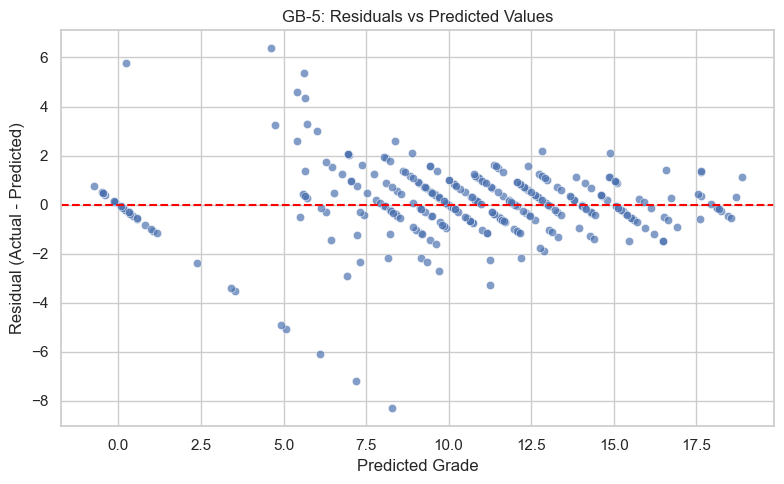

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=oof_predictions,
    y=residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Grade")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("GB-5: Residuals vs Predicted Values")

plt.tight_layout()

save_plot("GB5_Residuals_vs_Predicted.png")

Visualize residual distribution

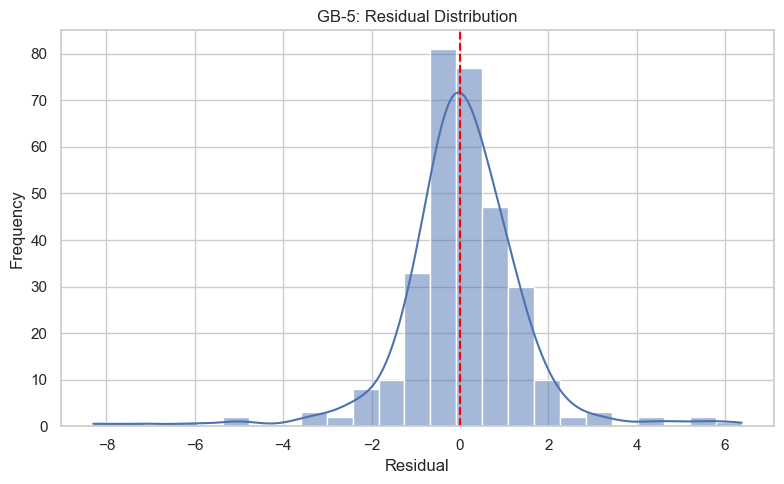

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=25,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.title("GB-5: Residual Distribution")

plt.tight_layout()

save_plot("GB5_Residual_Distribution.png")

Visualize absolute prediction errors

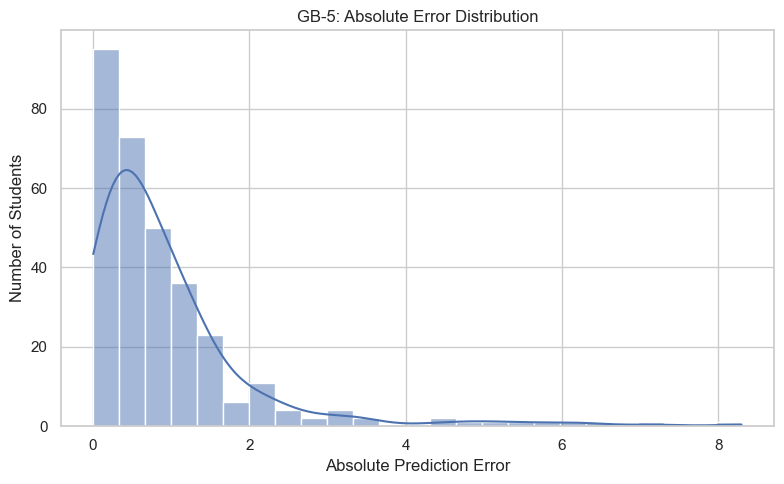

In [15]:
absolute_errors = np.abs(residuals)

plt.figure(figsize=(8, 5))

sns.histplot(
    absolute_errors,
    bins=25,
    kde=True
)

plt.xlabel("Absolute Prediction Error")
plt.ylabel("Number of Students")

plt.title("GB-5: Absolute Error Distribution")

plt.tight_layout()

save_plot("GB5_Absolute_Error_Distribution.png")

Calculate grade prediction accuracy

In [16]:
rounded_predictions = np.clip(
    np.rint(oof_predictions),
    0,
    20
).astype(int)

exact_accuracy = (
    np.mean(rounded_predictions == actual) * 100
)

within_1 = (
    np.mean(np.abs(actual - oof_predictions) <= 1)
    * 100
)

within_2 = (
    np.mean(np.abs(actual - oof_predictions) <= 2)
    * 100
)

print("=" * 60)
print("GB-5 GRADE PREDICTION ACCURACY")
print("=" * 60)

print(f"Exact Grade Accuracy : {exact_accuracy:.2f}%")
print(f"Within ±1 Grade      : {within_1:.2f}%")
print(f"Within ±2 Grades     : {within_2:.2f}%")

GB-5 GRADE PREDICTION ACCURACY
Exact Grade Accuracy : 43.99%
Within ±1 Grade      : 68.99%
Within ±2 Grades     : 89.56%


Visualize grade prediction accuracy

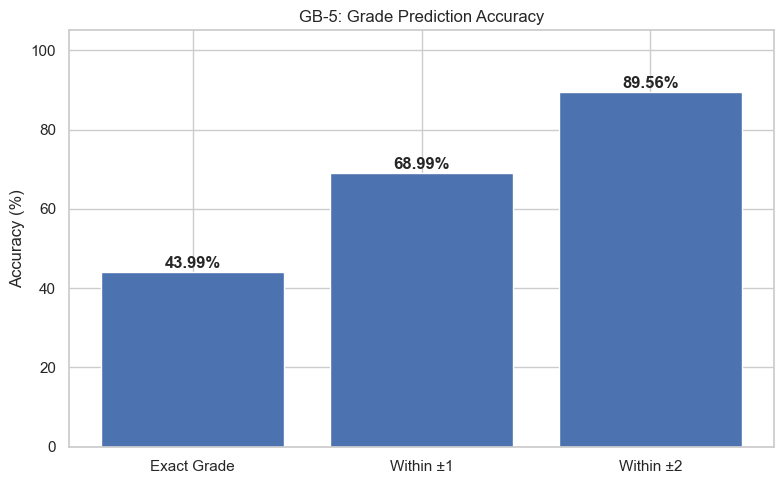

In [17]:
categories = [
    "Exact Grade",
    "Within ±1",
    "Within ±2"
]

values = [
    exact_accuracy,
    within_1,
    within_2
]

plt.figure(figsize=(8, 5))

bars = plt.bar(categories, values)

plt.ylabel("Accuracy (%)")
plt.title("GB-5: Grade Prediction Accuracy")

plt.ylim(0, 105)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

save_plot("GB5_Grade_Accuracy.png")

Calculate pass/fail classification metrics

In [18]:
actual_binary = (actual >= 10).astype(int)

predicted_binary = (
    oof_predictions >= 10
).astype(int)

pass_fail_accuracy = accuracy_score(
    actual_binary,
    predicted_binary
)

precision = precision_score(
    actual_binary,
    predicted_binary,
    zero_division=0
)

recall = recall_score(
    actual_binary,
    predicted_binary,
    zero_division=0
)

f1 = f1_score(
    actual_binary,
    predicted_binary,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    actual_binary,
    predicted_binary,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0 else 0
)

print("=" * 60)
print("GB-5 PASS/FAIL CLASSIFICATION")
print("=" * 60)

print(f"Accuracy    : {pass_fail_accuracy * 100:.2f}%")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

print("\nConfusion Matrix")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

GB-5 PASS/FAIL CLASSIFICATION
Accuracy    : 88.61%
Precision   : 0.9890
Recall      : 0.8404
Specificity : 0.9806
F1 Score    : 0.9086

Confusion Matrix
TN: 101
FP: 2
FN: 34
TP: 179


Visualize the pass/fail confusion matrix

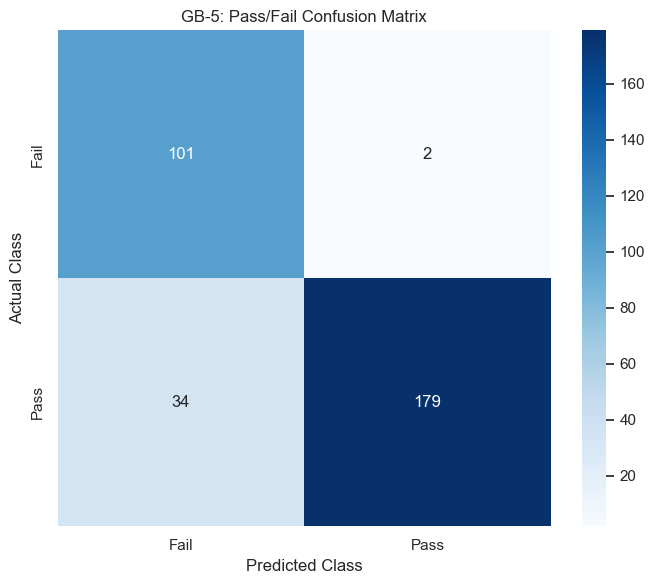

In [19]:
cm = confusion_matrix(
    actual_binary,
    predicted_binary,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("GB-5: Pass/Fail Confusion Matrix")

plt.tight_layout()

save_plot("GB5_Confusion_Matrix.png")

Visualize classification metrics

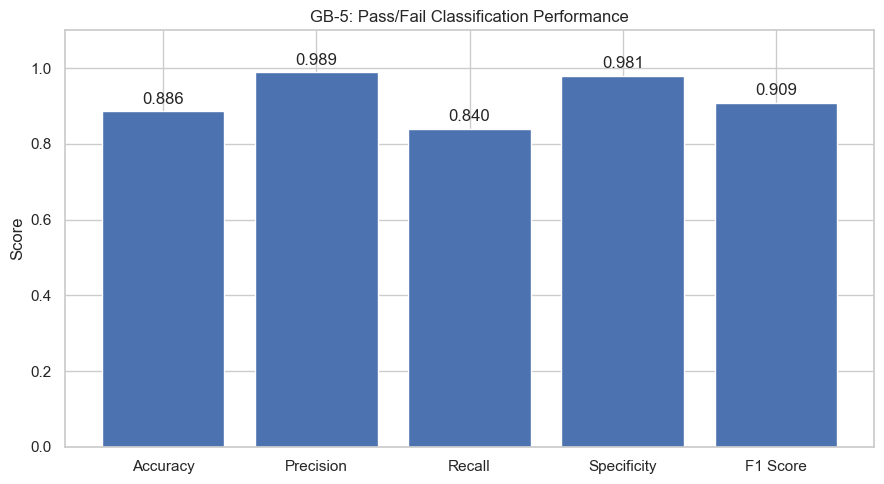

In [20]:
classification_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1 Score"
]

classification_values = [
    pass_fail_accuracy,
    precision,
    recall,
    specificity,
    f1
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    classification_names,
    classification_values
)

plt.ylim(0, 1.1)
plt.ylabel("Score")

plt.title("GB-5: Pass/Fail Classification Performance")

for bar, value in zip(bars, classification_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

save_plot("GB5_Classification_Metrics.png")

Generate a learning curve

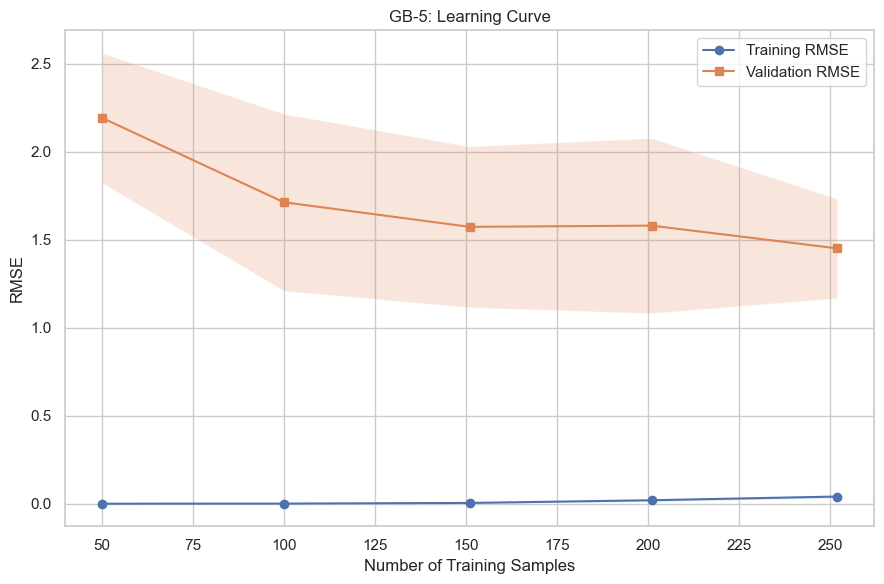

In [21]:
train_sizes, train_scores, val_scores = learning_curve(
    gb5_model,
    X_train,
    y_train,
    cv=cv,
    train_sizes=np.linspace(0.2, 1.0, 5),
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

train_rmse_curve = np.sqrt(-train_scores)
val_rmse_curve = np.sqrt(-val_scores)

train_mean = train_rmse_curve.mean(axis=1)
train_std = train_rmse_curve.std(axis=1)

val_mean = val_rmse_curve.mean(axis=1)
val_std = val_rmse_curve.std(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training RMSE"
)

plt.plot(
    train_sizes,
    val_mean,
    marker="s",
    label="Validation RMSE"
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

plt.xlabel("Number of Training Samples")
plt.ylabel("RMSE")

plt.title("GB-5: Learning Curve")
plt.legend()

plt.tight_layout()

save_plot("GB5_Learning_Curve.png")


Visualize overfitting gap

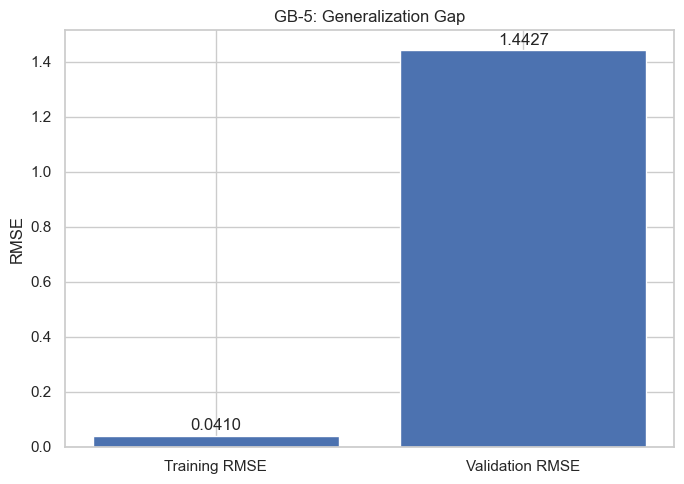

In [22]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Training RMSE", "Validation RMSE"],
    [train_rmse, val_rmse]
)

plt.ylabel("RMSE")
plt.title("GB-5: Generalization Gap")

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()

save_plot("GB5_Overfitting_Gap.png")

Train the final model on all training data

In [23]:
final_gb5 = clone(gb5_model)

final_gb5.fit(X_train, y_train)

print("Final GB-5 model trained successfully.")
print("Training samples:", len(X_train))
print("Features:", X_train.shape[1])

Final GB-5 model trained successfully.
Training samples: 316
Features: 58


Calculate and visualize feature importance

In [24]:
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_gb5.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(feature_importance_df.head(20))

feature_importance_df.to_csv(
    output_dir / "GB5_Feature_Importance.csv",
    index=False
)

,Feature,Importance
13,num__G2,0.768458
14,absences_log__absences,0.130726
36,cat__reason_home,0.028415
0,num__age,0.012895
12,num__G1,0.011282
6,num__famrel,0.005820
41,cat__guardian_other,0.004581
11,num__health,0.004033
42,cat__schoolsup_no,0.002899
8,num__goout,0.002707


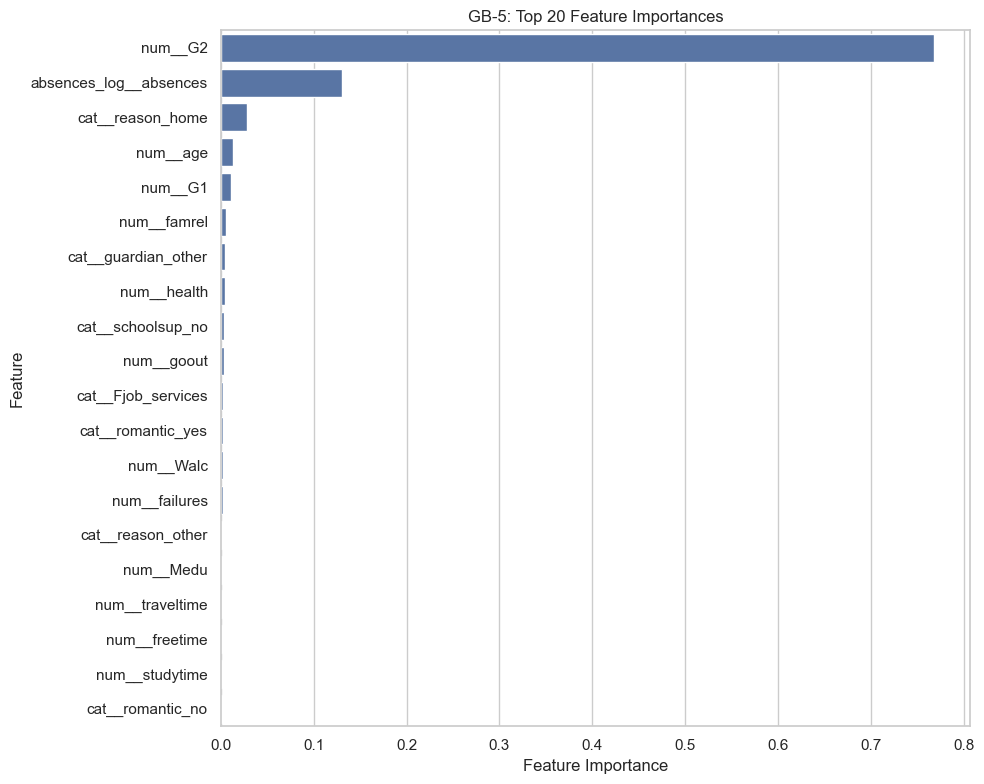

In [25]:
top_features = feature_importance_df.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("GB-5: Top 20 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()

save_plot("GB5_Feature_Importance.png")

Visualize training error across boosting stages

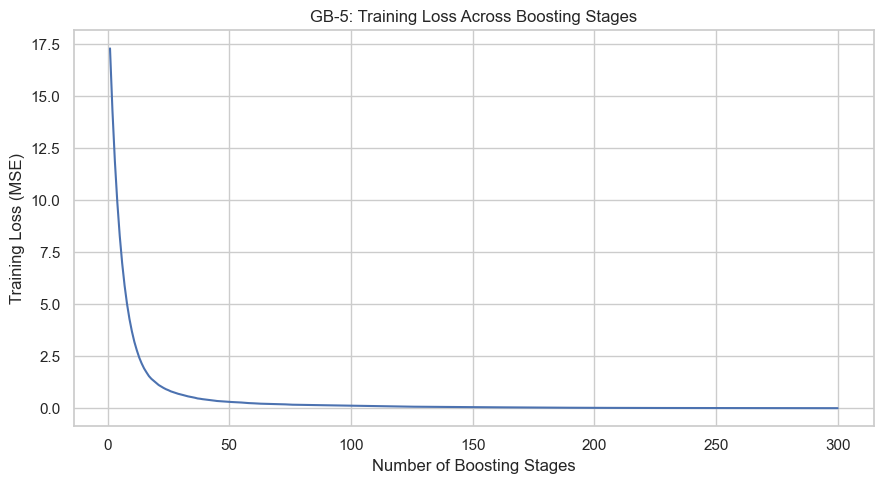

In [26]:
stage_numbers = np.arange(
    1,
    final_gb5.n_estimators_ + 1
)

training_deviance = final_gb5.train_score_

plt.figure(figsize=(9, 5))

plt.plot(
    stage_numbers,
    training_deviance
)

plt.xlabel("Number of Boosting Stages")
plt.ylabel("Training Loss (MSE)")

plt.title("GB-5: Training Loss Across Boosting Stages")

plt.tight_layout()

save_plot("GB5_Training_Loss.png")

Visualize validation error across boosting stage

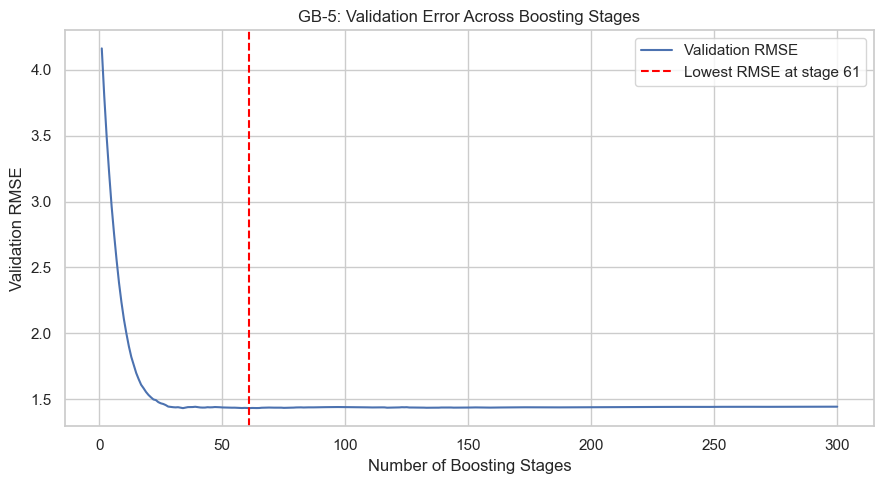

Lowest stage-wise validation RMSE at: 61
Stage-wise RMSE: 1.4313575125812537


In [27]:
stage_val_rmse = []

for train_idx, val_idx in cv.split(X_train):

    fold_model = clone(gb5_model)

    fold_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    X_val_fold = X_train.iloc[val_idx]
    y_val_fold = y_train.iloc[val_idx]

    fold_errors = []

    for predictions in fold_model.staged_predict(X_val_fold):

        rmse = np.sqrt(
            mean_squared_error(
                y_val_fold,
                predictions
            )
        )

        fold_errors.append(rmse)

    stage_val_rmse.append(fold_errors)

stage_val_rmse = np.array(stage_val_rmse)

mean_stage_rmse = stage_val_rmse.mean(axis=0)

best_stage = np.argmin(mean_stage_rmse) + 1

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, 301),
    mean_stage_rmse,
    label="Validation RMSE"
)

plt.axvline(
    best_stage,
    color="red",
    linestyle="--",
    label=f"Lowest RMSE at stage {best_stage}"
)

plt.xlabel("Number of Boosting Stages")
plt.ylabel("Validation RMSE")

plt.title("GB-5: Validation Error Across Boosting Stages")

plt.legend()
plt.tight_layout()

save_plot("GB5_Validation_Loss.png")

print("Lowest stage-wise validation RMSE at:", best_stage)
print("Stage-wise RMSE:", mean_stage_rmse[best_stage - 1])

Save the final trained GB-5 model

In [28]:
model_bundle = {
    "model": final_gb5,
    "model_name": "Gradient Boosting Regressor",
    "experiment": "GB-5",
    "features": X_train.columns.tolist(),
    "input_type": "preprocessed",
    "target": "G3",
    "pass_threshold": 10,
    "parameters": final_gb5.get_params(),
    "cv_validation_rmse": float(val_rmse),
    "cv_validation_mae": float(val_mae),
    "cv_validation_r2": float(val_r2)
}

model_path = (
    models_dir / "final_gradient_boosting_GB5.joblib"
)

joblib.dump(model_bundle, model_path)

print("Final model saved successfully.")
print("Path:", model_path)

Final model saved successfully.
Path: C:\Users\U S E R\Desktop\ML Assigment\project\models\final_gradient_boosting_GB5.joblib


Load and verify the saved model

In [29]:
loaded_bundle = joblib.load(model_path)

loaded_model = loaded_bundle["model"]

print("Model:", loaded_bundle["model_name"])
print("Experiment:", loaded_bundle["experiment"])
print("Number of features:", len(loaded_bundle["features"]))
print("Input type:", loaded_bundle["input_type"])

sample_predictions = loaded_model.predict(
    X_train.head(5)
)

print("\nSample predictions:")
print(sample_predictions)

Model: Gradient Boosting Regressor
Experiment: GB-5
Number of features: 58
Input type: preprocessed

Sample predictions:
[ 1.21177020e+01  1.40356458e+01 -1.33159684e-02  8.95248000e+00
  8.02505286e+00]


Load the held-out test dataset

In [30]:
test_df = pd.read_csv(
    processed_dir / "math_test_processed.csv"
)

X_test = test_df.drop(columns=["G3"])
y_test = test_df["G3"]

# Ensure identical feature names and order
expected_features = loaded_bundle["features"]

missing_features = set(expected_features) - set(X_test.columns)
extra_features = set(X_test.columns) - set(expected_features)

if missing_features or extra_features:
    raise ValueError(
        f"Missing features: {missing_features}\n"
        f"Extra features: {extra_features}"
    )

X_test = X_test[expected_features]

assert X_test.notna().all().all()
assert y_test.notna().all()

print("Test samples:", X_test.shape[0])
print("Test features:", X_test.shape[1])

Test samples: 79
Test features: 58


Evaluate the final model on the test dataset

In [31]:
test_predictions = loaded_model.predict(X_test)

test_mae = mean_absolute_error(
    y_test,
    test_predictions
)

test_mse = mean_squared_error(
    y_test,
    test_predictions
)

test_rmse = np.sqrt(test_mse)

test_r2 = r2_score(
    y_test,
    test_predictions
)

print("=" * 60)
print("FINAL GB-5 TEST SET RESULTS")
print("=" * 60)

print(f"Test MAE  : {test_mae:.4f}")
print(f"Test MSE  : {test_mse:.4f}")
print(f"Test RMSE : {test_rmse:.4f}")
print(f"Test R²   : {test_r2:.4f}")

print(f"\nCV Validation RMSE : {val_rmse:.4f}")
print(f"Test RMSE          : {test_rmse:.4f}")

FINAL GB-5 TEST SET RESULTS
Test MAE  : 1.2417
Test MSE  : 4.2311
Test RMSE : 2.0570
Test R²   : 0.7937

CV Validation RMSE : 1.4427
Test RMSE          : 2.0570


Evaluate test grade accuracy and pass/fail performance

In [32]:
test_actual = y_test.to_numpy()

test_rounded = np.clip(
    np.rint(test_predictions),
    0,
    20
).astype(int)

test_exact = np.mean(
    test_rounded == test_actual
) * 100

test_within_1 = np.mean(
    np.abs(test_actual - test_predictions) <= 1
) * 100

test_within_2 = np.mean(
    np.abs(test_actual - test_predictions) <= 2
) * 100

test_actual_binary = (
    test_actual >= 10
).astype(int)

test_predicted_binary = (
    test_predictions >= 10
).astype(int)

test_accuracy = accuracy_score(
    test_actual_binary,
    test_predicted_binary
)

test_precision = precision_score(
    test_actual_binary,
    test_predicted_binary,
    zero_division=0
)

test_recall = recall_score(
    test_actual_binary,
    test_predicted_binary,
    zero_division=0
)

test_f1 = f1_score(
    test_actual_binary,
    test_predicted_binary,
    zero_division=0
)

test_tn, test_fp, test_fn, test_tp = confusion_matrix(
    test_actual_binary,
    test_predicted_binary,
    labels=[0, 1]
).ravel()

test_specificity = (
    test_tn / (test_tn + test_fp)
    if (test_tn + test_fp) > 0 else 0
)

print("=" * 60)
print("FINAL TEST GRADE ACCURACY")
print("=" * 60)

print(f"Exact Accuracy  : {test_exact:.2f}%")
print(f"Within ±1 Grade : {test_within_1:.2f}%")
print(f"Within ±2 Grades: {test_within_2:.2f}%")

print("\nPASS/FAIL CLASSIFICATION")

print(f"Accuracy   : {test_accuracy * 100:.2f}%")
print(f"Precision  : {test_precision:.4f}")
print(f"Recall     : {test_recall:.4f}")
print(f"Specificity: {test_specificity:.4f}")
print(f"F1 Score   : {test_f1:.4f}")

print("\nCONFUSION MATRIX")
print("TN:", test_tn)
print("FP:", test_fp)
print("FN:", test_fn)
print("TP:", test_tp)

FINAL TEST GRADE ACCURACY
Exact Accuracy  : 37.97%
Within ±1 Grade : 58.23%
Within ±2 Grades: 88.61%

PASS/FAIL CLASSIFICATION
Accuracy   : 91.14%
Precision  : 1.0000
Recall     : 0.8654
Specificity: 1.0000
F1 Score   : 0.9278

CONFUSION MATRIX
TN: 27
FP: 0
FN: 7
TP: 45


Visualize final test predictions

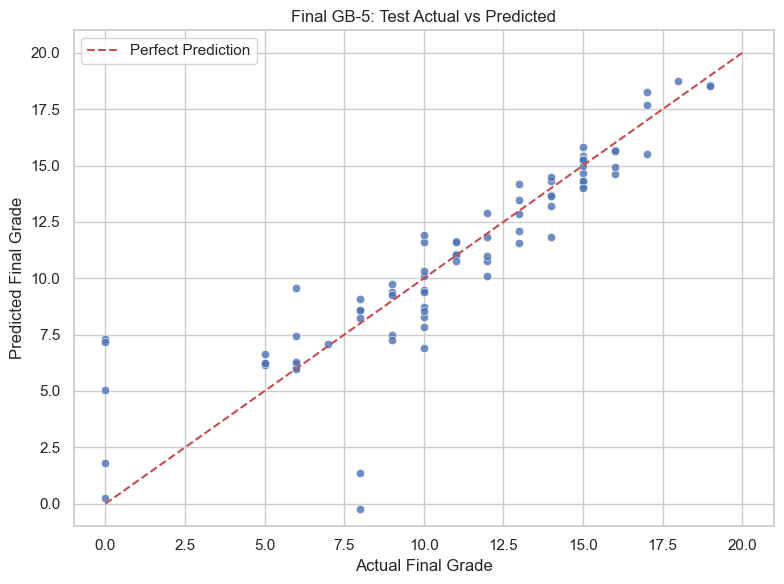

In [33]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=test_actual,
    y=test_predictions,
    alpha=0.8
)

plt.plot(
    [0, 20],
    [0, 20],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")

plt.title("Final GB-5: Test Actual vs Predicted")

plt.xlim(-1, 21)
plt.ylim(-1, 21)
plt.legend()

plt.tight_layout()

save_plot("GB5_Test_Actual_vs_Predicted.png")

Visualize the test confusion matrix

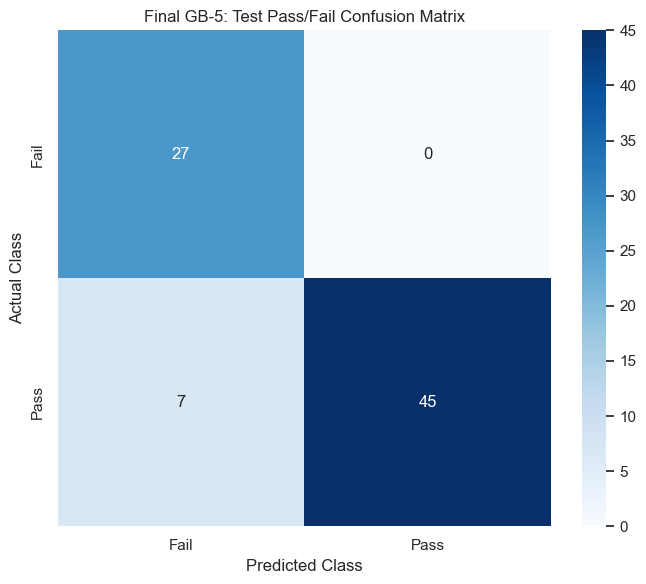

In [34]:
test_cm = confusion_matrix(
    test_actual_binary,
    test_predicted_binary,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Final GB-5: Test Pass/Fail Confusion Matrix")

plt.tight_layout()

save_plot("GB5_Test_Confusion_Matrix.png")

Save the final test results

In [35]:
test_results = pd.DataFrame([{
    "Model": "Gradient Boosting GB-5",

    "CV Validation RMSE": val_rmse,
    "Test MAE": test_mae,
    "Test MSE": test_mse,
    "Test RMSE": test_rmse,
    "Test R2": test_r2,

    "Exact Accuracy (%)": test_exact,
    "Within 1 Grade (%)": test_within_1,
    "Within 2 Grades (%)": test_within_2,

    "Pass/Fail Accuracy (%)": test_accuracy * 100,
    "Precision": test_precision,
    "Recall": test_recall,
    "Specificity": test_specificity,
    "F1 Score": test_f1,

    "TN": test_tn,
    "FP": test_fp,
    "FN": test_fn,
    "TP": test_tp
}])

test_results.to_csv(
    output_dir / "GB5_Final_Test_Results.csv",
    index=False
)

test_prediction_df = pd.DataFrame({
    "Actual G3": test_actual,
    "Predicted G3": test_predictions,
    "Rounded Predicted G3": test_rounded,
    "Absolute Error": np.abs(
        test_actual - test_predictions
    )
})

test_prediction_df.to_csv(
    output_dir / "GB5_Final_Test_Predictions.csv",
    index=False
)

display(test_results.round(4))

print("Final test results saved successfully.")

,Model,CV Validation RMSE,Test MAE,Test MSE,Test RMSE,Test R2,Exact Accuracy (%),Within 1 Grade (%),Within 2 Grades (%),Pass/Fail Accuracy (%),Precision,Recall,Specificity,F1 Score,TN,FP,FN,TP
0,Gradient Boosting GB-5,1.4427,1.2417,4.2311,2.057,0.7937,37.9747,58.2278,88.6076,91.1392,1.0,0.8654,1.0,0.9278,27,0,7,45


Final test results saved successfully.
